In [11]:
!pip install geodatasets geopandas folium


   ------------- -------------------------- 1/3 [branca]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   ---------------------------------------- 3/3 [folium]




[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import pandas as pd
import geopandas
import folium
import geodatasets
import matplotlib.pyplot as plt

In [ ]:
df1 = pd.read_csv("DV_EXP4.csv")

In [14]:
df = df1.loc[:, ("Year", "Name", "Country", "Latitude", "Longitude", "Type")]
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 63 entries, 0 to 62
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Year       63 non-null     int64  
 1   Name       63 non-null     str    
 2   Country    63 non-null     str    
 3   Latitude   63 non-null     float64
 4   Longitude  63 non-null     float64
 5   Type       63 non-null     str    
dtypes: float64(2), int64(1), str(3)
memory usage: 4.9 KB


In [15]:
geometry = geopandas.points_from_xy(df.Longitude, df.Latitude)
geo_df = geopandas.GeoDataFrame(
    df[["Year", "Name", "Country", "Latitude", "Longitude", "Type"]], geometry=geometry
)

geo_df.head()

,Year,Name,Country,Latitude,Longitude,Type,geometry
0,2010,Tungurahua,Ecuador,-1.467,-78.442,Stratovolcano,POINT (-78.442 -1.467)
1,2010,Eyjafjallajokull,Iceland,63.630,-19.620,Stratovolcano,POINT (-19.62 63.63)
2,2010,Pacaya,Guatemala,14.381,-90.601,Complex volcano,POINT (-90.601 14.381)
3,2010,Sarigan,United States,16.708,145.780,Stratovolcano,POINT (145.78 16.708)
4,2010,Karangetang [Api Siau],Indonesia,2.780,125.480,Stratovolcano,POINT (125.48 2.78)


In [16]:
world = geopandas.read_file(geodatasets.get_path("naturalearth.land"))
df.Type.unique()

<ArrowStringArray>
[     'Stratovolcano',    'Complex volcano',     'Shield volcano',
 'Subglacial volcano',          'Lava dome',            'Caldera']
Length: 6, dtype: str

Text(0.5, 1.0, 'Volcanoes')

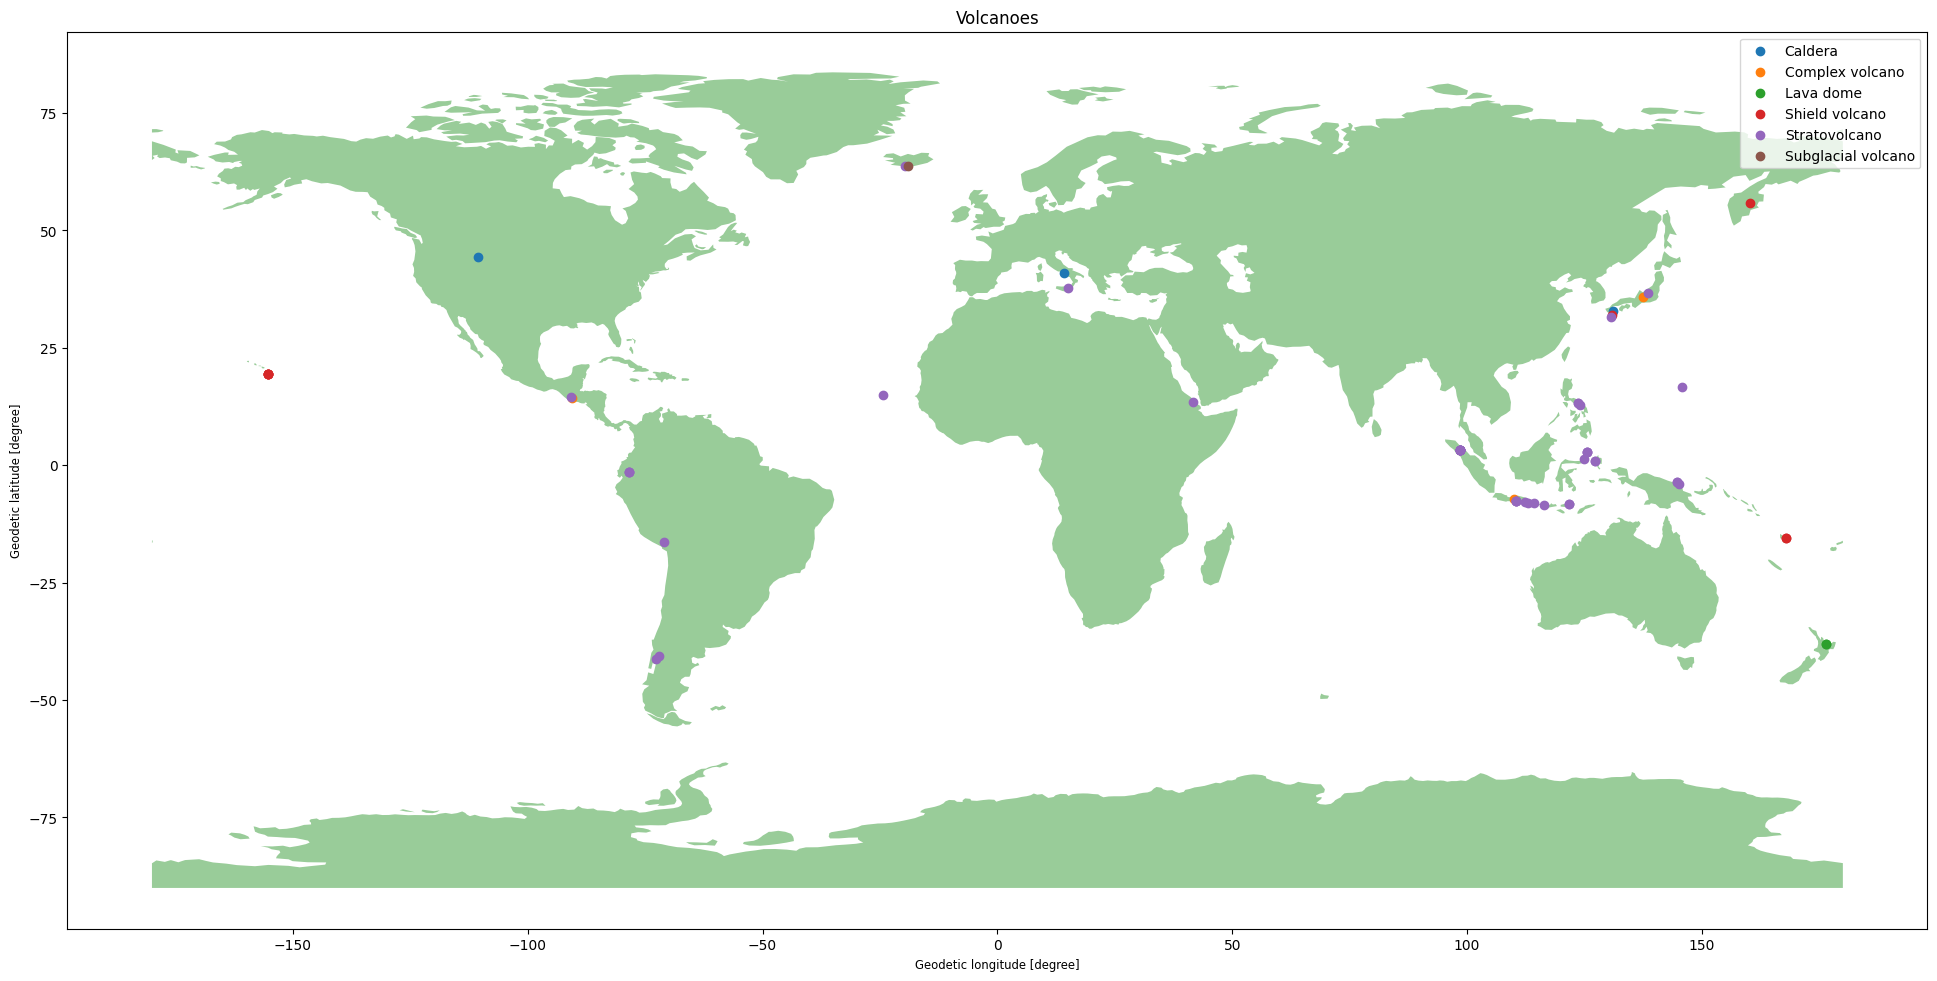

In [17]:
fig, ax = plt.subplots(figsize=(24, 18))
world.plot(ax=ax, alpha=0.4, color="green")
geo_df.plot(column="Type", ax=ax, legend=True)
plt.title("Volcanoes")